# ImmoAnalyse — exploration des résultats du pipeline

**Contexte.** Cinq sources immobilières hétérogènes (CSV, Excel, JSON) ont été chargées, harmonisées, validées par règles,
dédoublonnées puis exportées par `python -m src.main`. Ce notebook ne retraite rien : il **lit les fichiers produits**
(`reports/`, `data/processed/`, `data/quarantine/`) et les présente.

> **À retenir avant toute lecture.** Les données sont **synthétiques** et les prix de vente sont des **prix demandés**
> (annonces), pas des prix de transaction conclue. Les chiffres décrivent ce jeu de données, pas le marché sénégalais.

Plan : 1. chargement · 2. qualité · 3. distributions · 4. résultats par type et par ville · 5. conclusions et limites.

## 1. Contexte et chargement des résultats du pipeline

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Racine du projet : on remonte jusqu'au dossier qui contient config/ (le notebook peut être lancé de n'importe où)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config").is_dir())
sys.path.insert(0, str(ROOT))

from config import settings
from src.analysis import analyser, charger_biens, NOTE_DONNEES

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
BLEU, ORANGE, GRIS, VERT = "#2b6cb0", "#dd8452", "#8c8c8c", "#3a9a6b"

rapport = json.loads((settings.REPORTS_DIR / "quality_report.json").read_text(encoding="utf-8"))
quarantaine = pd.read_csv(settings.QUARANTINE_DIR / "quarantaine.csv", encoding="utf-8-sig")
biens = charger_biens(settings.PROCESSED_DIR / "biens_dedupliques.csv")
analyse = analyser(biens)
d = analyse["donnees"]
print("Date de référence du traitement :", rapport["date_reference"])
print(f"Biens uniques analysés : {len(biens):,} | mis en quarantaine : {len(quarantaine):,}")
print(NOTE_DONNEES)

Date de référence du traitement : 2026-10-29
Biens uniques analysés : 2,979 | mis en quarantaine : 190
Données synthétiques ; prix de vente = prix demandés (annonces), pas des transactions conclues : ces résultats décrivent le jeu de données, pas le marché.


## 2. Qualité des données

### 2.1 Bilan : de 3 184 lignes reçues aux données retenues

Chaque ligne reçue finit dans **une seule** catégorie : doublon exact écarté, quarantaine, conservée avec avertissement,
ou entièrement conforme. Le taux global de conformité est calculé sur les **évalués** (reçus moins doublons exacts).

In [2]:
v, s = rapport["volumes"], rapport["statuts_finaux"]
bilan = pd.DataFrame([
    ("Lignes reçues", v["total_recus"], None),
    ("Doublons exacts écartés", v["doublons_exacts"], 100 * v["doublons_exacts"] / v["total_recus"]),
    ("Évalués (reçus - doublons)", s["evalues"], None),
    ("  Entièrement conformes", s["entierement_conformes"], s["taux_entierement_conformes_pct"]),
    ("  Conservés avec avertissement", s["conserves_avec_avertissement"], 100 * s["conserves_avec_avertissement"] / s["evalues"]),
    ("  En quarantaine", s["quarantaine"], s["taux_quarantaine_pct"]),
], columns=["catégorie", "nombre", "taux (%)"])
print("Dénominateur des taux : reçus pour les doublons, évalués pour les autres lignes.")
print(f"Contrôle de somme : {s['controle_somme_ok']} | corrigés (drapeau transversal) : {s['corriges']:,} | valeurs inférées : {s['avec_valeur_inferee']:,}")
bilan

Dénominateur des taux : reçus pour les doublons, évalués pour les autres lignes.
Contrôle de somme : True | corrigés (drapeau transversal) : 1,375 | valeurs inférées : 1,576


,catégorie,nombre,taux (%)
0,Lignes reçues,3184,NaN
1,Doublons exacts écartés,15,0.5
2,Évalués (reçus - doublons),3169,NaN
3,Entièrement conformes,2405,75.9
4,Conservés avec avertissement,574,18.1
5,En quarantaine,190,6.0


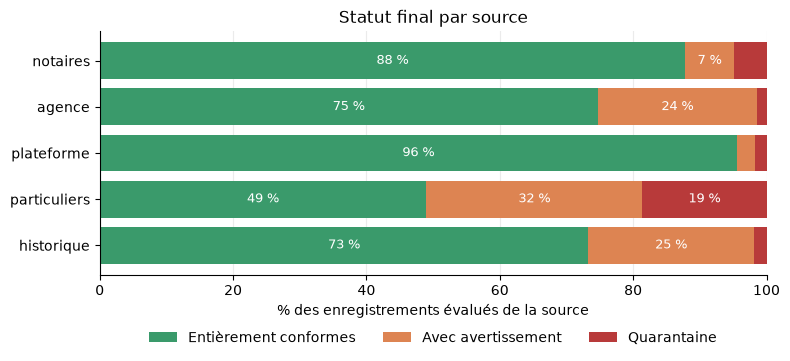

,evalues,entierement_conformes,conserves_avec_avertissement,quarantaine,corriges
notaires,410.0,360.0,30.0,20.0,0.0
agence,640.0,478.0,153.0,9.0,304.0
plateforme,860.0,822.0,23.0,15.0,264.0
particuliers,731.0,358.0,237.0,136.0,449.0
historique,528.0,387.0,131.0,10.0,358.0


In [3]:
par_source = pd.DataFrame(rapport["statuts_par_source"]).T.drop(columns="controle_somme_ok").astype(float)
ordre = ["entierement_conformes", "conserves_avec_avertissement", "quarantaine"]
libelles = ["Entièrement conformes", "Avec avertissement", "Quarantaine"]
couleurs = [VERT, ORANGE, "#b83a3a"]
pct = par_source[ordre].div(par_source["evalues"], axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 3.8))
gauche = np.zeros(len(pct))
for col, lib, c in zip(ordre, libelles, couleurs):
    ax.barh(pct.index, pct[col], left=gauche, label=lib, color=c)
    for y, (val, g) in enumerate(zip(pct[col], gauche)):
        if val > 6:
            ax.text(g + val / 2, y, f"{val:.0f} %", ha="center", va="center", color="white", fontsize=9)
    gauche += pct[col].values
ax.set_xlim(0, 100); ax.invert_yaxis()
ax.set_xlabel("% des enregistrements évalués de la source")
ax.set_title("Statut final par source")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.tight_layout(); plt.show()
par_source[["evalues", *ordre, "corriges"]]

La source **particuliers** concentre la quarantaine (prix et surfaces manquants, surfaces écrites « quatre-vingt »).
La **plateforme** est la plus propre. L'**agence** et l'**historique** ont peu de quarantaine mais beaucoup d'avertissements
(loyers sans périodicité, chambres et salles de bain atypiques). Les **notaires**, source annoncée comme très fiable,
perdent des actes à cause de 14 montants manquants et de 6 dates impossibles.

### 2.2 Conformité par règle

Taux = conformes / **évaluables**. Les cas non évaluables (ex. règle sur le loyer pour une vente) sont comptés à part
et ne sont jamais considérés conformes par défaut.

In [4]:
regles = pd.DataFrame(rapport["regles"])
regles = regles[["regle", "action", "evaluables", "conformes", "non_conformes", "non_evaluables", "taux_conformite"]]
regles.columns = ["règle", "action", "évaluables (dénominateur)", "conformes", "non conformes", "non évaluables", "taux de conformité (%)"]
regles.sort_values("taux de conformité (%)")

,règle,action,évaluables (dénominateur),conformes,non conformes,non évaluables,taux de conformité (%)
22,chambre_avec_plusieurs_chambres,avertissement,148,19,129,3021,12.8
8,periodicite_valide,avertissement,498,173,325,2671,34.7
20,sdb_superieures_chambres_plus_marge,avertissement,1899,1778,121,1270,93.6
3,loyer_positif,quarantaine,498,474,24,2671,95.2
16,prix_hors_fourchette_type,avertissement,2598,2518,80,571,96.9
4,surface_positive,quarantaine,3169,3081,88,0,97.2
2,prix_vente_positif,quarantaine,2669,2598,71,500,97.3
5,date_collecte_valide,quarantaine,3169,3163,6,0,99.8
6,date_collecte_non_future,quarantaine,3163,3158,5,6,99.8
17,prix_m2_hors_fourchette_type,avertissement,2541,2537,4,628,99.8


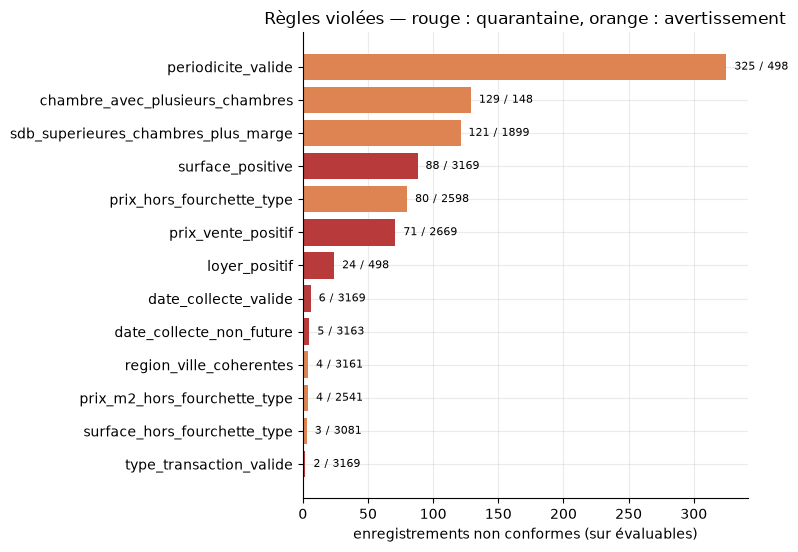

In [5]:
r = pd.DataFrame(rapport["regles"]).query("non_conformes > 0").sort_values("non_conformes")
fig, ax = plt.subplots(figsize=(8, 0.34 * len(r) + 1.2))
couleur = r["action"].map({"quarantaine": "#b83a3a", "avertissement": ORANGE})
ax.barh(r["regle"], r["non_conformes"], color=couleur)
for y, (n, den) in enumerate(zip(r["non_conformes"], r["evaluables"])):
    ax.text(n, y, f"  {n} / {den}", va="center", fontsize=8)
ax.set_xlabel("enregistrements non conformes (sur évaluables)")
ax.set_title("Règles violées — rouge : quarantaine, orange : avertissement")
plt.tight_layout(); plt.show()

### 2.3 Motifs de quarantaine

Un enregistrement peut cumuler plusieurs motifs : la somme des barres peut dépasser le nombre d'enregistrements en quarantaine.

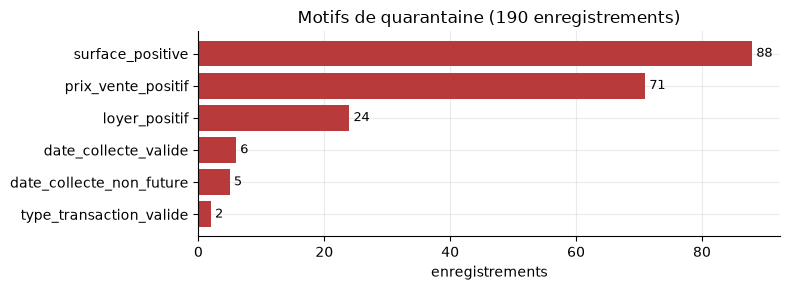

,en quarantaine
source,
agence,9
historique,10
notaires,20
particuliers,136
plateforme,15


In [6]:
motifs = pd.Series(rapport["motifs_quarantaine"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(motifs.index, motifs.values, color="#b83a3a")
for y, n in enumerate(motifs.values):
    ax.text(n, y, f" {n}", va="center", fontsize=9)
ax.set_xlabel("enregistrements"); ax.set_title(f"Motifs de quarantaine ({len(quarantaine)} enregistrements)")
plt.tight_layout(); plt.show()
quarantaine.groupby("source").size().rename("en quarantaine").to_frame()

In [7]:
# Exemples concrets : la valeur brute reçue et le motif, pour chaque type de motif
exemples = (quarantaine.assign(motif=quarantaine["motifs_quarantaine"].str.split(" \\| ").str[0].str.replace(r" \[.*", "", regex=True))
            .groupby("motif").head(2).sort_values("motif"))
exemples[["motif", "source", "id_local", "brut_montant", "brut_surface", "brut_date_collecte", "erreurs_conversion"]]

,motif,source,id_local,brut_montant,brut_surface,brut_date_collecte,erreurs_conversion
29,date_collecte_non_future,plateforme,PLT-00014,91358000,111.6,2028-12-01,NaN
31,date_collecte_non_future,plateforme,PLT-00077,64862000,78.4,2028-12-01,NaN
8,date_collecte_valide,notaires,NOT-02394,69528000.0,238.3,32/13/2024,date_collecte:date_impossible:32/13/2024
9,date_collecte_valide,notaires,NOT-02396,30816000.0,54.5,32/13/2024,date_collecte:date_impossible:32/13/2024
51,loyer_positif,particuliers,PRT-01485,NaN,222.4,04/11/2022,NaN
52,loyer_positif,particuliers,PRT-01496,NaN,427,2024-01-17,NaN
0,prix_vente_positif,notaires,NOT-02208,NaN,73.3,2021-03-13,NaN
1,prix_vente_positif,notaires,NOT-02245,NaN,110.4,2024-04-02,NaN
20,surface_positive,agence,AGT-00826,31286000,-30,12/09/2023,NaN
24,surface_positive,agence,AGT-01065,47828000,-25,02/09/2018,NaN


### 2.4 Valeurs manquantes et erreurs de conversion

In [8]:
manq = pd.DataFrame(rapport["valeurs_manquantes_par_colonne"]).T
manq = manq[manq["denominateur"] > 0][["manquantes", "denominateur", "taux_pct"]].sort_values("taux_pct", ascending=False)
manq.columns = ["manquantes", "dénominateur (lignes des sources qui fournissent la colonne)", "taux (%)"]
print("Une colonne que la source ne fournit pas (ex. type_transaction pour l'agence) sort du dénominateur.")
manq

Une colonne que la source ne fournit pas (ex. type_transaction pour l'agence) sort du dénominateur.


,manquantes,dénominateur (lignes des sources qui fournissent la colonne),taux (%)
surface,80,3184,2.5
montant,75,3184,2.4
ville,8,3184,0.2
id_local,0,3184,0.0
type_bien,0,3184,0.0
region,0,3184,0.0
chambres,0,2309,0.0
date_collecte,0,3184,0.0
statut,0,2656,0.0
type_transaction,0,1606,0.0


In [9]:
conv = pd.DataFrame(rapport["erreurs_conversion_par_champ"]).T[["erreurs", "par_motif", "par_source"]]
conv

,erreurs,par_motif,par_source
date_collecte,6,{'date_impossible': 6},{'notaires': 6}
loyer,1,{'prix_non_numerique': 1},{'particuliers': 1}
prix,16,{'prix_non_numerique': 16},"{'plateforme': 5, 'particuliers': 1, 'historiq..."
surface,4,{'surface_non_numerique': 4},{'particuliers': 4}
type_transaction,2,{'transaction_non_deductible': 2},{'agence': 2}


## 3. Distributions

Ventes et locations sont **toujours séparées** : un loyer mensuel de 250 000 FCFA n'est pas comparable à un prix de vente.
Les prix de vente sont affichés en échelle logarithmique car ils s'étalent sur plusieurs ordres de grandeur.

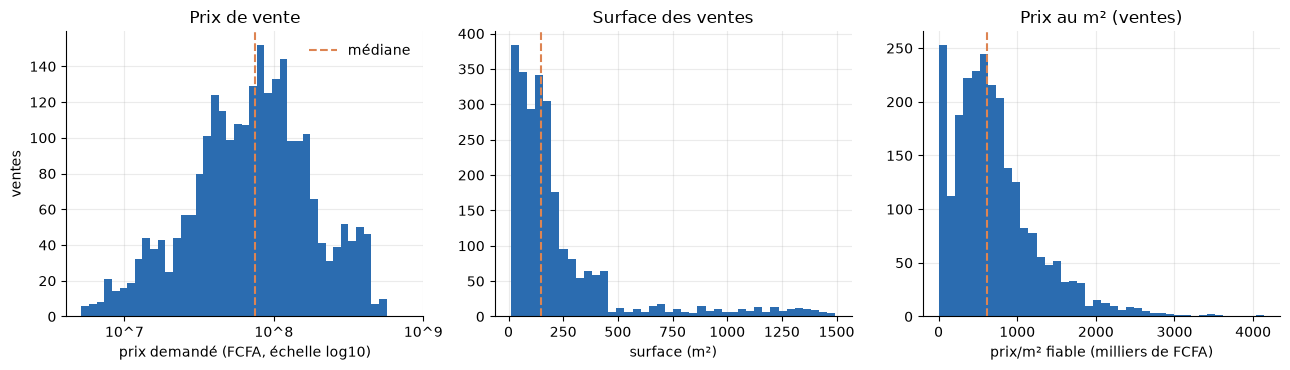

,n,moyenne,ecart_type,min,q1,mediane,q3,max
variable,,,,,,,,
prix demandé (FCFA),2530,"104,616,589.5","98,308,544.9","5,156,000.0","38,818,250.0","74,948,500.0","129,624,750.0","567,559,000.0"
surface (m²),2530,236.4,285.3,10.2,70.8,146.9,247.1,"1,494.8"
prix/m² fiable (FCFA),2434,"714,145.6","538,760.4","6,647.9","344,523.8","612,057.4","947,709.5","4,135,138.2"


In [10]:
ventes = d[d["type_transaction"] == "vente"]
locations = d[d["type_transaction"] == "location"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].hist(np.log10(ventes["prix"].dropna()), bins=40, color=BLEU)
axes[0].set_xlabel("prix demandé (FCFA, échelle log10)"); axes[0].set_ylabel("ventes")
ticks = [7, 8, 9]; axes[0].set_xticks(ticks, [f"10^{t}" for t in ticks])
axes[0].axvline(np.log10(ventes["prix"].median()), color=ORANGE, ls="--", label="médiane"); axes[0].legend(frameon=False)
axes[0].set_title("Prix de vente")
axes[1].hist(ventes["surface"].dropna(), bins=40, color=BLEU)
axes[1].set_xlabel("surface (m²)"); axes[1].set_title("Surface des ventes")
axes[1].axvline(ventes["surface"].median(), color=ORANGE, ls="--")
axes[2].hist(ventes["prix_m2_fiable"].dropna() / 1e3, bins=40, color=BLEU)
axes[2].set_xlabel("prix/m² fiable (milliers de FCFA)"); axes[2].set_title("Prix au m² (ventes)")
axes[2].axvline(ventes["prix_m2_fiable"].median() / 1e3, color=ORANGE, ls="--")
plt.tight_layout(); plt.show()
analyse["tables"]["descriptif"].query("transaction == 'vente'").set_index("variable").drop(columns="transaction")

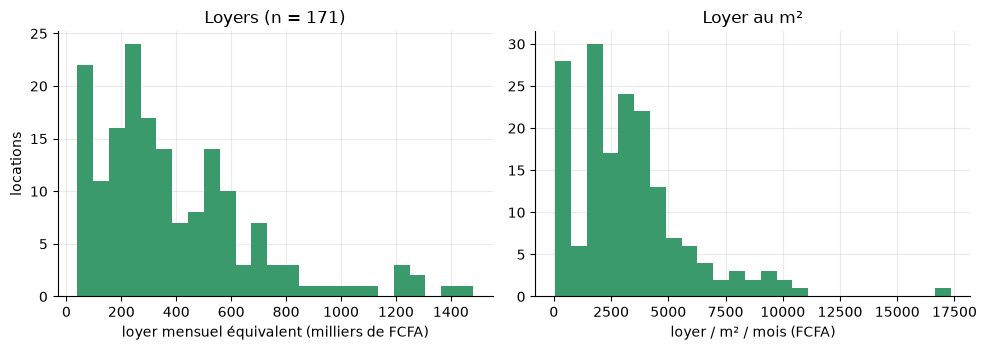

278 locations sur 449 n'ont aucune périodicité (agence, particuliers) : leur loyer n'est pas converti en loyer mensuel, car la périodicité n'est jamais devinée.


,n,moyenne,ecart_type,min,q1,mediane,q3,max
variable,,,,,,,,
loyer mensuel équivalent (FCFA),171,"395,292.4","293,077.8","40,000.0","187,500.0","315,000.0","542,500.0","1,480,000.0"
surface (m²),449,265.1,328.4,10.2,80.1,149.8,241.1,"1,475.2"
loyer/m²/mois fiable (FCFA),171,"3,272.7","2,578.7",55.4,"1,697.0","2,963.4","4,271.3","17,327.6"


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(locations["loyer_mensuel"].dropna() / 1e3, bins=25, color=VERT)
axes[0].set_xlabel("loyer mensuel équivalent (milliers de FCFA)"); axes[0].set_ylabel("locations")
axes[0].set_title(f"Loyers (n = {locations['loyer_mensuel'].notna().sum()})")
axes[1].hist(locations["loyer_m2_mensuel"].dropna(), bins=25, color=VERT)
axes[1].set_xlabel("loyer / m² / mois (FCFA)"); axes[1].set_title("Loyer au m²")
plt.tight_layout(); plt.show()
res = analyse["resume"]
print(f"{res['locations_sans_periodicite_exclues']} locations sur {res['locations']} n'ont aucune périodicité (agence, particuliers) : "
      "leur loyer n'est pas converti en loyer mensuel, car la périodicité n'est jamais devinée.")
analyse["tables"]["descriptif"].query("transaction == 'location'").set_index("variable").drop(columns="transaction")

## 4. Résultats par type de bien, par ville et par source

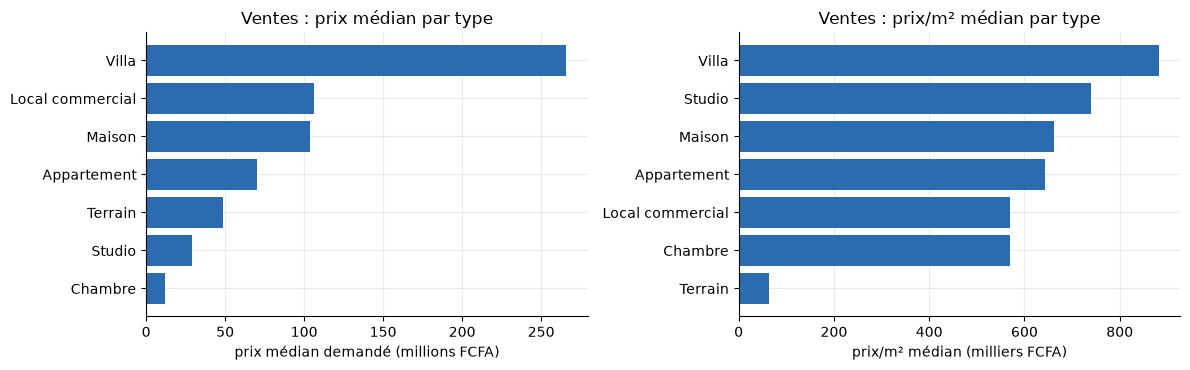

,type_bien,n_biens,prix_median (M FCFA),surface_mediane,n_m2_fiables,prix_m2_fiable_median (k FCFA)
0,Appartement,590,70.2,110.0,556,643.5
1,Maison,534,103.7,157.1,520,661.1
2,Villa,448,266.0,297.4,427,882.4
3,Terrain,355,48.8,766.3,349,64.4
4,Studio,302,29.2,39.1,289,738.8
5,Chambre,157,11.7,19.6,156,570.2
6,Local commercial,144,106.5,177.8,137,570.5


In [12]:
t = analyse["tables"]["ventes_par_type_bien"].copy()
t["prix_median (M FCFA)"] = t["prix_median"] / 1e6
t["prix_m2_fiable_median (k FCFA)"] = t["prix_m2_fiable_median"] / 1e3
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
o = t.sort_values("prix_median (M FCFA)")
axes[0].barh(o["type_bien"], o["prix_median (M FCFA)"], color=BLEU); axes[0].set_xlabel("prix médian demandé (millions FCFA)")
axes[0].set_title("Ventes : prix médian par type")
o = t.sort_values("prix_m2_fiable_median (k FCFA)")
axes[1].barh(o["type_bien"], o["prix_m2_fiable_median (k FCFA)"], color=BLEU); axes[1].set_xlabel("prix/m² médian (milliers FCFA)")
axes[1].set_title("Ventes : prix/m² médian par type")
plt.tight_layout(); plt.show()
t[["type_bien", "n_biens", "prix_median (M FCFA)", "surface_mediane", "n_m2_fiables", "prix_m2_fiable_median (k FCFA)"]]

Le **terrain** a le prix/m² le plus bas parce que sa surface est très grande, pas parce qu'il est « bon marché » :
la comparaison du prix/m² entre un terrain et un studio n'a pas de sens économique.

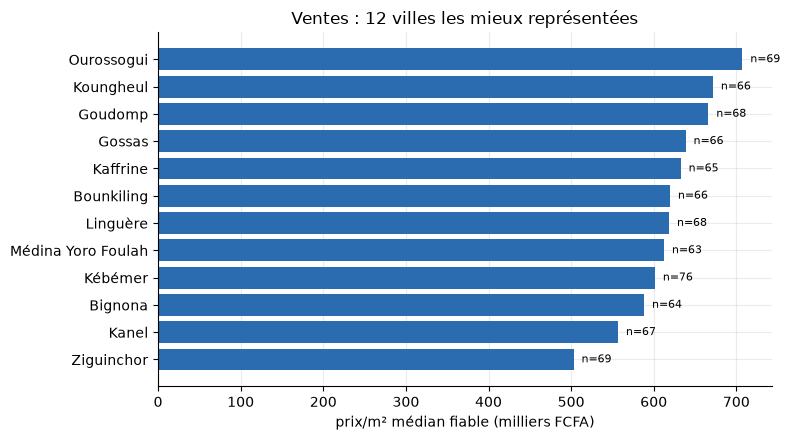

Villes avec moins de 5 ventes (effectif faible, à lire avec prudence) : 0 sur 47


In [13]:
v = analyse["tables"]["ventes_par_ville"]
top = v[~v["effectif_faible"]].nlargest(12, "n_biens").sort_values("prix_m2_fiable_median")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top["ville"], top["prix_m2_fiable_median"] / 1e3, color=BLEU)
for y, (val, n) in enumerate(zip(top["prix_m2_fiable_median"] / 1e3, top["n_biens"])):
    ax.text(val, y, f"  n={n}", va="center", fontsize=8)
ax.set_xlabel("prix/m² médian fiable (milliers FCFA)")
ax.set_title("Ventes : 12 villes les mieux représentées")
plt.tight_layout(); plt.show()
print(f"Villes avec moins de {settings.ANALYSE_N_MIN_GROUPE} ventes (effectif faible, à lire avec prudence) :",
      int(v['effectif_faible'].sum()), "sur", len(v))

In [14]:
analyse["tables"]["ventes_par_source"][["source", "n_biens", "prix_median", "surface_mediane", "n_m2_fiables", "prix_m2_fiable_median"]]

,source,n_biens,prix_median,surface_mediane,n_m2_fiables,prix_m2_fiable_median
0,plateforme,674,"79,722,000.0",147.8,647,"636,806.1"
1,agence,525,"80,538,000.0",154.9,505,"625,500.0"
2,historique,518,"67,640,000.0",135.4,503,"600,498.3"
3,particuliers,423,"62,030,000.0",140.0,407,"530,826.9"
4,notaires,390,"80,857,500.0",155.1,372,"633,218.2"


La comparaison par **source** reste indicative : les notaires déclarent des actes conclus, les autres canaux des annonces.
Pour les locations, seule la plateforme fournit une périodicité ; les autres sources n'entrent donc pas dans les loyers mensuels.

In [15]:
analyse["tables"]["locations_par_type_bien"][["type_bien", "n_biens", "loyer_mensuel_median", "n_m2_fiables", "loyer_m2_mensuel_median"]]

,type_bien,n_biens,loyer_mensuel_median,n_m2_fiables,loyer_m2_mensuel_median
0,Appartement,114,"370,000.0",53,"3,107.1"
1,Maison,94,"545,000.0",31,"3,610.4"
2,Terrain,82,"160,000.0",29,194.1
3,Villa,66,"850,000.0",21,"3,120.3"
4,Studio,54,"160,000.0",23,"3,971.1"
5,Chambre,24,"70,000.0",8,"3,870.3"
6,Local commercial,15,"592,500.0",6,"3,016.4"


## 5. Conclusions et limites

In [16]:
res, q = analyse["resume"], rapport["statuts_finaux"]
print(f"- Qualité : {q['taux_entierement_conformes_pct']} % des {q['evalues']:,} enregistrements évalués sont entièrement conformes, "
      f"{q['taux_quarantaine_pct']} % sont en quarantaine ; le reste est conservé avec avertissement.")
print(f"- Rapprochement : {rapport['rapprochement']['enregistrements_fusionnes_en_doublon']} doublon probable fusionné, "
      f"{rapport['rapprochement']['paires_conflit']} paires en conflit de prix (non fusionnées).")
print(f"- Prix/m² : calculé sur {res['ventes_avec_prix_m2_fiable']:,} ventes fiables ; {res['ventes_exclues_du_prix_m2']} exclues (atypiques ou en conflit).")
print(f"- Loyers : {res['locations_avec_loyer_mensuel']} locations sur {res['locations']} ont une périodicité connue.")

- Qualité : 75.89 % des 3,169 enregistrements évalués sont entièrement conformes, 6.0 % sont en quarantaine ; le reste est conservé avec avertissement.
- Rapprochement : 0 doublon probable fusionné, 7 paires en conflit de prix (non fusionnées).
- Prix/m² : calculé sur 2,434 ventes fiables ; 96 exclues (atypiques ou en conflit).
- Loyers : 171 locations sur 449 ont une périodicité connue.


**Conclusions**

- Le pipeline lit les trois formats, détecte les anomalies attendues (dates impossibles, prix « à négocier », surfaces en lettres,
  prix à 0, surfaces négatives, dates futures) et les met en quarantaine avec un motif, sans jamais deviner une valeur.
- Les corrections retenues sont des conversions sûres (prix en millions, séparateurs, casse, synonymes, dates JJ/MM/AAAA) et sont toutes tracées
  dans `journal_corrections.csv`.
- Les prix médians et prix/m² dépendent fortement du type de bien : toute comparaison doit se faire **à type égal**.

**Limites**

- **Données synthétiques et prix demandés** : aucune conclusion sur le marché réel.
- **Périodicité manquante** (agence, particuliers) : 278 loyers ne sont pas ramenés au mois ; l'hypothèse « mensuel » est probable mais non prouvée (décision 10, à arbitrer).
- **Rapprochement prudent** : aucun doublon probable n'existe entre les sources avec les seuils retenus (±1 % de surface, ±30 jours, ±5 % de prix) ;
  les 7 conflits de prix sont probablement des coïncidences, non des preuves d'un même bien.
- **Seuils pédagogiques** : les règles de plausibilité (chambres, salles de bain, fourchettes de prix) sont des hypothèses du cahier des charges ;
  certaines signalent beaucoup d'enregistrements (décision 24).
- **Effectifs faibles** par ville : les médianes de petits groupes sont signalées (`effectif_faible`) mais pas masquées.